# Project and folder name:- 
**Title:-** Online Shopping Customer Satisfaction Analysis  
**Folder name:-** online-shopping-satisfaction-analysis

# 1. Business problem
An e-commerce operations manager sees that some orders get very low satisfaction scores, but does not know what drives them. Is it slow delivery, discounts, order value, or the product category? This project finds the main drivers of `Satisfaction_Score` and flags the orders that need attention, so that the company can protect repeat purchases and reduce complaints.

## The four questions
1. What does the satisfaction score look like overall?
2. Do `Delivery_Days` and `Discount_Percent` affect the satisfaction score?
3. Does the score differ by product category, device, payment method and city?
4. Which orders need attention (**At Risk** = satisfaction score below 60)?

## Data dictionary
| Column | Type | Meaning | Valid values / range |
|---|---|---|---|
| Order_ID | text | Unique order id | O1001 to O1250 |
| Order_Date | date | Date of order (DD-MM-YYYY in the raw file) | last ~2 years |
| City | category | Delivery city | Delhi, Mumbai, Bengaluru, Kolkata, Noida |
| Product_Category | category | Product type | Fashion, Electronics, Home_Kitchen, Beauty |
| Payment_Method | category | How the customer paid | UPI, Card, COD, Wallet |
| Payment_Method| category | Device used to order | Mobile, Desktop, Tablet |
| Customer_Age | number | Age in years | 18 to 60 |
| Order_Value_INR | number | Order amount in rupees | > 0 |
| Delivery_Days | number | Days taken to deliver | 1 to 10 |
| Discount_Percent | number | Discount given | 0 to 100 |
| Satisfaction_Score | number | **Outcome**: customer satisfaction | 0 to 100 |

## 2. Load and inspect the data

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
raw = pd.read_csv('../data/raw/online_shopping_data.csv')
print('Shape (rows, columns):', raw.shape)
print(raw.head().to_string())



ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Order_ID            255 non-null    str    
 1   Order_Date          255 non-null    str    
 2   City                255 non-null    str    
 3   Product_Category    255 non-null    str    
 4   Payment_Method      249 non-null    str    
 5   Device_Type         255 non-null    str    
 6   Customer_Age        250 non-null    float64
 7   Order_Value_INR     255 non-null    int64  
 8   Delivery_Days       251 non-null    float64
 9   Discount_Percent    255 non-null    int64  
 10  Satisfaction_Score  250 non-null    float64
dtypes: float64(3), int64(2), str(6)
memory usage: 22.0 KB


In [ ]:
print(raw.describe().round(2).to_string())

       Customer_Age  Order_Value_INR  Delivery_Days  Discount_Percent  Satisfaction_Score
count        250.00           255.00         251.00            255.00              250.00
mean          30.28          3740.69           4.54             17.45               70.72
std            7.04          4058.54           2.25             19.04                8.64
min           18.00           153.00           1.00              0.00               47.40
25%           25.00          1229.00           3.00              9.00               65.45
50%           30.00          2130.00           4.00             17.00               70.90
75%           35.00          4682.00           6.00             22.00               76.40
max           56.00         25802.00          10.00            250.00               91.10


In [ ]:
print('Missing values per column:')
print(raw.isna().sum())
print()
print('Duplicate rows:', raw.duplicated().sum())
print('Unique Order_IDs:', raw['Order_ID'].nunique(), 'out of', len(raw))
print()
print('City values:')
print(raw['City'].value_counts().to_string())

Missing values per column:
Order_ID              0
Order_Date            0
City                  0
Product_Category      0
Payment_Method        6
Device_Type           0
Customer_Age          5
Order_Value_INR       0
Delivery_Days         4
Discount_Percent      0
Satisfaction_Score    5
dtype: int64

Duplicate rows: 5
Unique Order_IDs: 250 out of 255

City values:
City
Delhi         72
Bengaluru     53
Mumbai        53
Kolkata       36
Noida         34
kolkata        1
 bengaluru     1
Delhi          1
KOLKATA        1
delhi          1
 Noida         1
BENGALURU      1


## 3. Clean the data

In [ ]:
df = raw.copy()

df = df.drop_duplicates().copy()

df['City'] = df['City'].str.strip().str.title()

df['Order_Date'] = pd.to_datetime(df['Order_Date'], dayfirst=True)

bad = df['Discount_Percent'] > 100
print('Impossible discount values:', df.loc[bad, 'Discount_Percent'].tolist())
df.loc[bad, 'Discount_Percent'] = np.nan

print('Rows with missing Satisfaction_Score dropped:', df['Satisfaction_Score'].isna().sum())
df = df.dropna(subset=['Satisfaction_Score'])

for col in ['Customer_Age', 'Delivery_Days', 'Discount_Percent']:
    df[col] = df[col].fillna(df[col].median())

df['Payment_Method'] = df['Payment_Method'].fillna('Unknown')

df = df.reset_index(drop=True)
print()
print('Shape after cleaning:', df.shape)
print('Missing values left:', int(df.isna().sum().sum()))
print('Duplicates left:', int(df.duplicated().sum()))
print(df['City'].value_counts().to_string())

Impossible discount values: [250, 135]
Rows with missing Satisfaction_Score dropped: 5

Shape after cleaning: (245, 11)
Missing values left: 0
Duplicates left: 0
City
Delhi        69
Bengaluru    54
Mumbai       51
Kolkata      37
Noida        34


**Why I cleaned it this way**
- **Duplicates removed** (255 to 250 rows), because the same order must be counted only once.
- **City text standardised**: 12 city spellings collapsed into the 5 real cities.
- **Impossible discounts** (250 and 135) set to missing and then filled with the median. I do not know the true value, and 250% is clearly wrong.
- **Missing `Satisfaction_Score`** rows dropped (5 rows), because this is the outcome I am analysing. Filling it with a guess would hide the real pattern.
- **Median** used for age, delivery days and discount, since it is not pulled up by extreme values.
- **Payment method** left as "Unknown" instead of guessing.

## 4. Create new columns

In [ ]:

df['Discount_Amount_INR'] = (df['Order_Value_INR'] * df['Discount_Percent'] / 100).round(0)

def satisfaction_band(score):
    if score < 60:
        return 'At Risk'
    elif score < 75:
        return 'Average'
    return 'Happy'
df['Satisfaction_Band'] = df['Satisfaction_Score'].apply(satisfaction_band)

df['Delivery_Speed'] = pd.cut(df['Delivery_Days'], bins=[0, 2, 5, 10], labels=['Fast (1-2)', 'Normal (3-5)', 'Slow (6-10)'])

df['Age_Group'] = pd.cut(df['Customer_Age'], bins=[17, 24, 34, 44, 100], labels=['18-24', '25-34', '35-44', '45+'])

df['Order_Month'] = df['Order_Date'].dt.to_period('M').astype(str)

print(df[['Order_ID', 'Discount_Amount_INR', 'Satisfaction_Band', 'Delivery_Speed', 'Age_Group', 'Order_Month']].head().to_string())
print()
print(df['Satisfaction_Band'].value_counts().to_string())

  Order_ID  Discount_Amount_INR Satisfaction_Band Delivery_Speed Age_Group Order_Month
0    O1212                162.0           Average     Fast (1-2)     35-44     2025-12
1    O1055                417.0           Average    Slow (6-10)     25-34     2026-09
2    O1125                692.0             Happy   Normal (3-5)     25-34     2026-03
3    O1227                168.0           Average   Normal (3-5)     25-34     2025-09
4    O1230                199.0           Average    Slow (6-10)     25-34     2026-09

Satisfaction_Band
Average    147
Happy       71
At Risk     27


## 5. Analysis

### Q1. What does the satisfaction score look like overall?

count    245.00
mean      70.59
std        8.63
min       47.40
25%       65.20
50%       70.50
75%       76.40
max       91.10
Skewness: -0.24


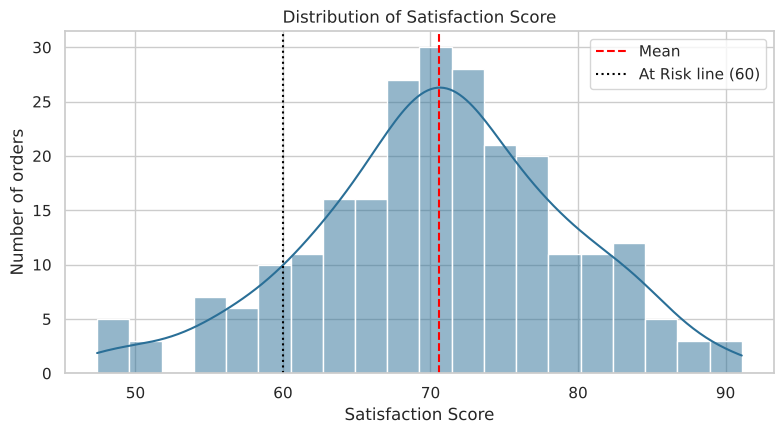

In [ ]:
print(df['Satisfaction_Score'].describe().round(2).to_string())
print('Skewness:', round(df['Satisfaction_Score'].skew(), 2))

plt.figure(figsize=(8, 4.5))
sns.histplot(df['Satisfaction_Score'], bins=20, kde=True, color='#2a6f97')
plt.axvline(df['Satisfaction_Score'].mean(), color='red', linestyle='--', label='Mean')
plt.axvline(60, color='black', linestyle=':', label='At Risk line (60)')
plt.title('Distribution of Satisfaction Score')
plt.xlabel('Satisfaction Score'); plt.ylabel('Number of orders'); plt.legend()
plt.tight_layout(); plt.savefig('../images/01_satisfaction_distribution.png', dpi=150)
plt.show()

### Q2. Do Delivery_Days and Discount_Percent affect satisfaction?

Customer_Age          0.04
Order_Value_INR      -0.01
Delivery_Days        -0.59
Discount_Percent      0.49
Satisfaction_Score    1.00


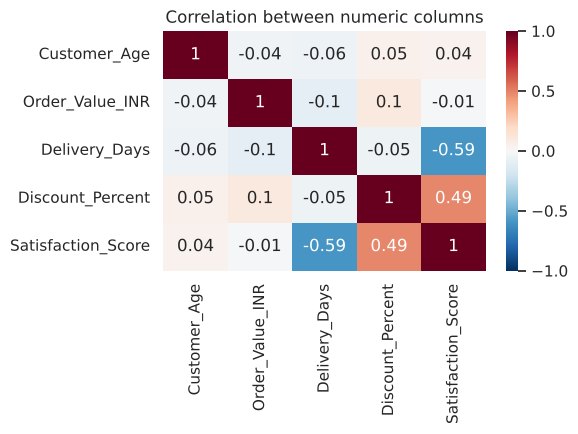

In [ ]:
num_cols = ['Customer_Age', 'Order_Value_INR', 'Delivery_Days', 'Discount_Percent', 'Satisfaction_Score']
corr = df[num_cols].corr().round(2)
print(corr['Satisfaction_Score'].to_string())

plt.figure(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Correlation between numeric columns')
plt.tight_layout(); plt.savefig('../images/02_correlation_heatmap.png', dpi=150)
plt.show()

                count  mean
Delivery_Speed             
Fast (1-2)         49  77.5
Normal (3-5)      121  71.2
Slow (6-10)        75  65.0

                  count  mean
Discount_Percent             
0-10%                75  65.4
11-20%               96  70.9
21%+                 74  75.4


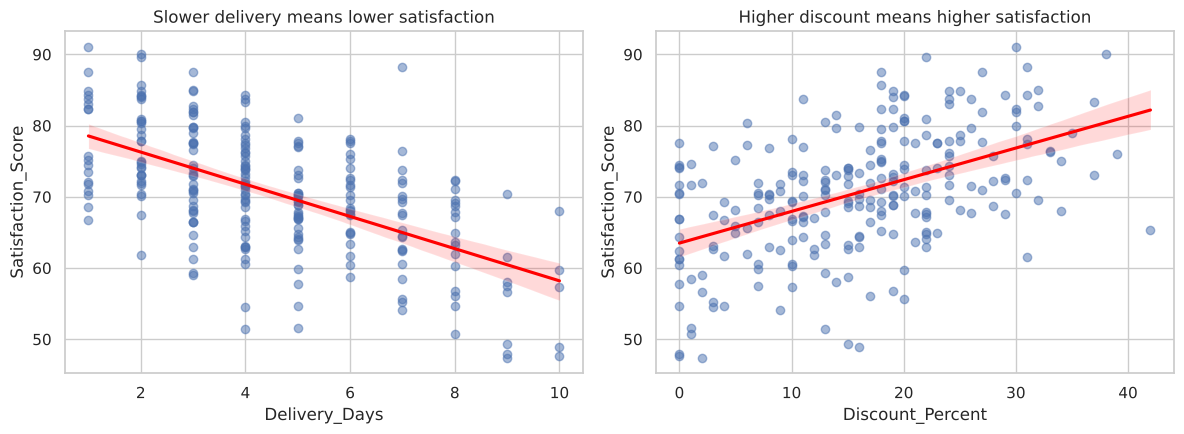

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.regplot(data=df, x='Delivery_Days', y='Satisfaction_Score', ax=axes[0],
            scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
axes[0].set_title('Slower delivery means lower satisfaction')
sns.regplot(data=df, x='Discount_Percent', y='Satisfaction_Score', ax=axes[1],
            scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})
axes[1].set_title('Higher discount means higher satisfaction')
plt.tight_layout(); plt.savefig('../images/03_delivery_discount_vs_satisfaction.png', dpi=150)
plt.show()

print(df.groupby('Delivery_Speed', observed=True)['Satisfaction_Score'].agg(['count', 'mean']).round(1).to_string())
print()
print(df.groupby(pd.cut(df['Discount_Percent'], [-1, 10, 20, 50], labels=['0-10%', '11-20%', '21%+']), observed=True)['Satisfaction_Score'].agg(['count', 'mean']).round(1).to_string())

### Q3. Does satisfaction differ by category, device, payment method and city?

                  count  mean
Product_Category             
Beauty               33  73.2
Home_Kitchen         68  73.1
Fashion              97  68.9
Electronics          47  68.5

             count  mean
Device_Type             
Tablet          18  73.4
Desktop         60  70.8
Mobile         167  70.2

                count  mean
Payment_Method             
Unknown             6  74.6
Card               53  71.4
COD                53  71.2
UPI               108  70.4
Wallet             25  67.4

           count  mean
City                  
Delhi         69  71.1
Noida         34  71.1
Kolkata       37  71.0
Bengaluru     54  70.5
Mumbai        51  69.4



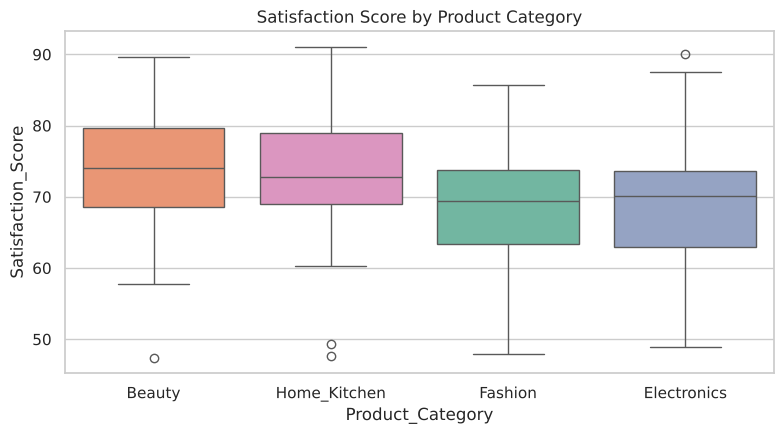

In [ ]:
for col in ['Product_Category', 'Device_Type', 'Payment_Method', 'City']:
    print(df.groupby(col)['Satisfaction_Score'].agg(['count', 'mean']).round(1).sort_values('mean', ascending=False).to_string())
    print()

plt.figure(figsize=(8, 4.5))
order = df.groupby('Product_Category')['Satisfaction_Score'].mean().sort_values(ascending=False).index
sns.boxplot(data=df, x='Product_Category', y='Satisfaction_Score', order=order, palette='Set2', hue='Product_Category', legend=False)
plt.title('Satisfaction Score by Product Category')
plt.tight_layout(); plt.savefig('../images/04_category_satisfaction.png', dpi=150)
plt.show()

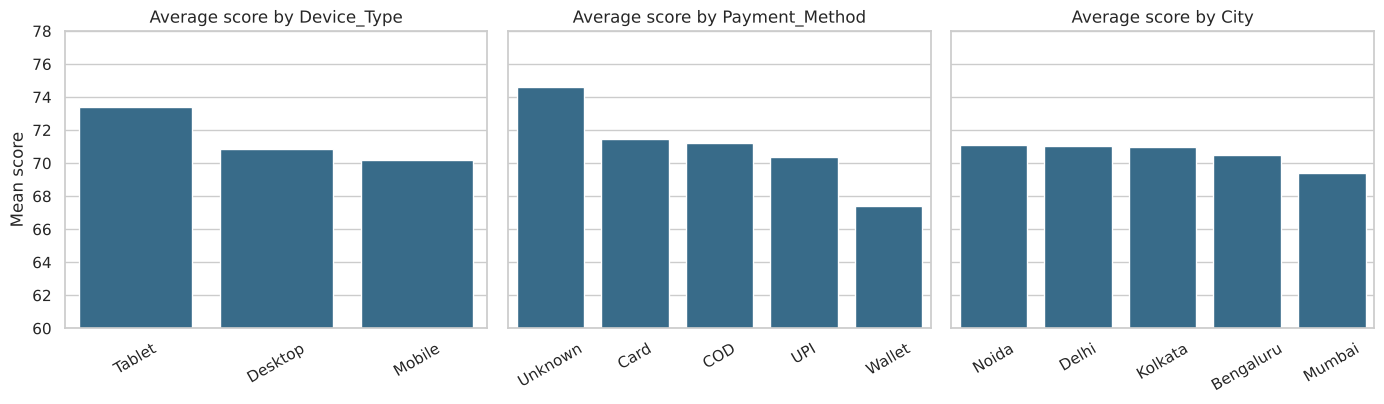

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, col in zip(axes, ['Device_Type', 'Payment_Method', 'City']):
    means = df.groupby(col)['Satisfaction_Score'].mean().sort_values(ascending=False)
    sns.barplot(x=means.index, y=means.values, ax=ax, color='#2a6f97')
    ax.set_title(f'Average score by {col}'); ax.set_xlabel(''); ax.set_ylabel('Mean score')
    ax.set_ylim(60, 78); ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig('../images/05_device_payment_city.png', dpi=150)
plt.show()

### Q4. Which orders need attention (At Risk, score below 60)?

At Risk orders: 27 out of 245 (11.0%)

At Risk share by delivery speed (%):
Delivery_Speed
Fast (1-2)       0.0
Normal (3-5)     6.6
Slow (6-10)     25.3

At Risk share by product category (%):
Product_Category
Beauty           9.1
Electronics     17.0
Fashion         14.4
Home_Kitchen     2.9

Average discount: At Risk vs others
Satisfaction_Band
False    16.9
True      7.9

Order_ID      City Product_Category  Delivery_Days  Discount_Percent  Satisfaction_Score
   O1136    Mumbai           Beauty            9.0               2.0                47.4
   O1216 Bengaluru     Home_Kitchen           10.0               0.0                47.6
   O1246    Mumbai          Fashion            9.0               0.0                47.9
   O1049    Mumbai      Electronics           10.0              16.0                48.9
   O1100     Delhi     Home_Kitchen            9.0              15.0                49.3
   O1235    Mumbai          Fashion            8.0               1.0                50.

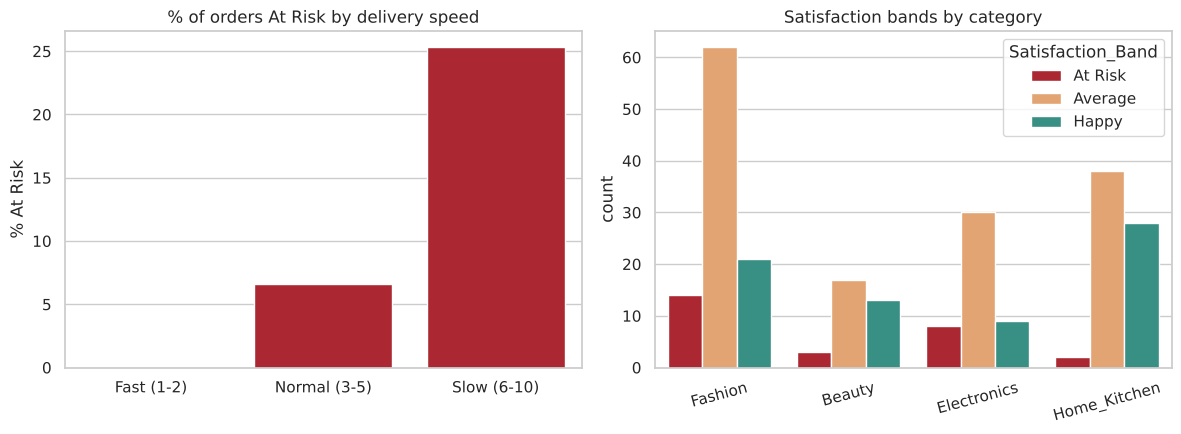

In [ ]:
at_risk = df[df['Satisfaction_Band'] == 'At Risk']
print('At Risk orders:', len(at_risk), 'out of', len(df), f'({len(at_risk) / len(df) * 100:.1f}%)')
print()
print('At Risk share by delivery speed (%):')
print((df.groupby('Delivery_Speed', observed=True)['Satisfaction_Band'].apply(lambda s: (s == 'At Risk').mean() * 100)).round(1).to_string())
print()
print('At Risk share by product category (%):')
print((df.groupby('Product_Category')['Satisfaction_Band'].apply(lambda s: (s == 'At Risk').mean() * 100)).round(1).to_string())
print()
print('Average discount: At Risk vs others')
print(df.groupby(df['Satisfaction_Band'] == 'At Risk')['Discount_Percent'].mean().round(1).to_string())
print()
print(at_risk.sort_values('Satisfaction_Score')[['Order_ID', 'City', 'Product_Category', 'Delivery_Days', 'Discount_Percent', 'Satisfaction_Score']].head(10).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
share = df.groupby('Delivery_Speed', observed=True)['Satisfaction_Band'].apply(lambda s: (s == 'At Risk').mean() * 100)
sns.barplot(x=share.index.astype(str), y=share.values, ax=axes[0], color='#c1121f')
axes[0].set_title('% of orders At Risk by delivery speed'); axes[0].set_xlabel(''); axes[0].set_ylabel('% At Risk')
sns.countplot(data=df, x='Product_Category', hue='Satisfaction_Band', hue_order=['At Risk', 'Average', 'Happy'],
              palette=['#c1121f', '#f4a261', '#2a9d8f'], ax=axes[1])
axes[1].set_title('Satisfaction bands by category'); axes[1].set_xlabel(''); axes[1].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.savefig('../images/06_at_risk_orders.png', dpi=150)
plt.show()

### Extra: monthly trend

             orders  avg_score
Order_Month                   
2026-06           7       73.0
2026-07           9       71.5
2026-08          11       68.9
2026-09          17       71.2
2026-10          10       75.2
2026-11           8       70.3


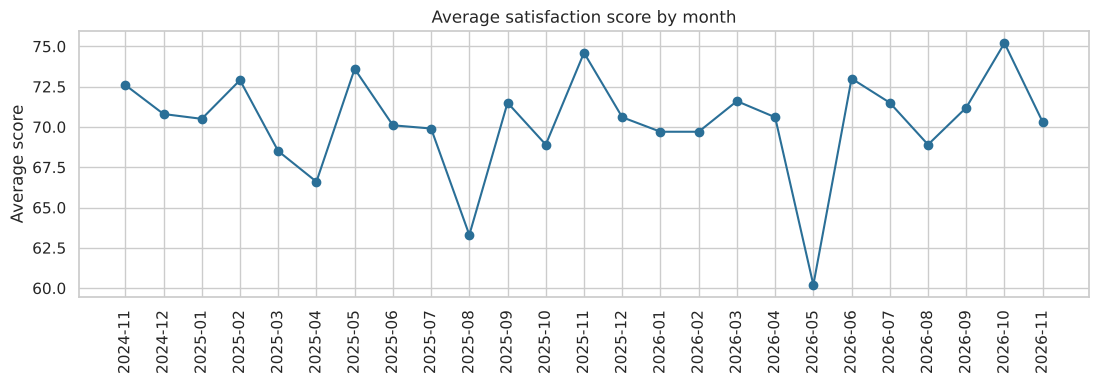

In [ ]:
monthly = df.groupby('Order_Month').agg(orders=('Order_ID', 'count'), avg_score=('Satisfaction_Score', 'mean')).round(1)
print(monthly.tail(6).to_string())

plt.figure(figsize=(11, 4))
plt.plot(monthly.index, monthly['avg_score'], marker='o', color='#2a6f97')
plt.xticks(rotation=90); plt.ylabel('Average score'); plt.title('Average satisfaction score by month')
plt.tight_layout(); plt.savefig('../images/07_monthly_trend.png', dpi=150)
plt.show()

Monthly averages move up and down a lot because some months have very few orders, so I do not read a trend into this chart.

## 6. Key insights
1. The average satisfaction score is **70.6** out of 100, and **11.0% of orders (27 of 245)** are At Risk (score below 60).
2. **Delivery time is the biggest driver.** Correlation is about -0.59. Fast deliveries (1-2 days) average 77.5, slow ones (6-10 days) average 65.0.
3. **Slow delivery is where the At Risk orders are.** About 25% of slow orders are At Risk, compared with 7% for normal and 0% for fast.
4. **Discounts help satisfaction** (correlation about +0.49). Orders with 21%+ discount average 75.4, versus 65.4 for 0-10%.
5. **Order value and customer age do not matter** (correlations near 0), so we should not target service by these.
6. **Beauty and Home_Kitchen customers are happier** (about 73) than Fashion and Electronics customers (about 69). Fashion also has the slowest average delivery (4.9 days).
7. Device, payment method and city show only small differences. Wallet looks lowest but has just 25 orders.

## 7. Recommendations for the manager
1. **Cut delivery time first.** Aim to deliver most orders within 5 days. Review couriers and warehouses for Fashion, which is the slowest category and the largest (97 orders).
2. **Add an alert for slow orders.** Orders passing 6 days should trigger a proactive message or follow-up, since this group has the most At Risk customers.
3. **Use targeted discounts or coupons** for customers who had a slow delivery, to recover satisfaction.
4. **Investigate Fashion and Electronics** (lowest scores) for product quality and return issues.
5. **Do not segment service by age or order value.** These have no effect on satisfaction in this data.
6. **Collect more data on Wallet and Tablet orders** before making decisions, because their sample sizes are small.

*Note: this is a synthetic practice dataset, so the findings show the method, not real market facts.*

## 8. Save the cleaned file

In [ ]:
out = df.copy()
out['Order_Date'] = out['Order_Date'].dt.strftime('%Y-%m-%d')
out.to_csv('../data/processed/online_shopping_data_clean.csv', index=False)
print('Saved:', out.shape)

Saved: (245, 16)
